# Turing's model for reaction-diffusion pattern formation

### Introduction

Spots and stripes appear throughout nature, for example on animal coats, shells and fish. In 1952 Alan Turing showed mathematically that such patterns can arise spontaneously from a surprisingly simple mechanism. Two chemicals react with each other and diffuse through space, and a uniform mixture can become unstable and break up into a regular spatial pattern. This is counter-intuitive, because diffusion normally smooths out differences in concentration. Here, if the two chemicals diffuse at sufficiently different rates, diffusion is exactly what destabilises the uniform state. This idea is known as a *diffusion-driven* or *Turing instability*, and reaction-diffusion models of this kind are still widely used to study pattern formation.
This project investigates two questions:

1. **For which parameter values does a uniform steady state of a two-species reaction-diffusion system become unstable when diffusion is added?**
2. **What spacing (wavelength) does the theory predict for the resulting pattern, and does a numerical simulation agree?**

The first question has a mathematical answer in the form of inequalities that the reaction kinetics and the diffusion coefficients must satisfy. The second turns these into testable predictions. The aim is not just to reproduce a pretty picture, but to show that the mathematics *predicts* when and how the pattern forms, and to check this against an independent numerical experiment.

##### Approach

1. **Theory.** For a general pair of reaction functions $f(u,v)$ and $g(u,v)$ we linearize around the uniform steady state and analyse how small perturbations of different spatial wavelengths grow or decay. This uses the Jacobian matrix, its eigenvalues and Fourier modes, and leads to explicit conditions for a Turing instability, as well as a prediction for the wavelength of the fastest-growing mode.
2. **Concrete model.** The general conditions do not specify $f$ and $g$, so to test them we choose the Schnakenberg model.
3. **Simulation.** We solve the full nonlinear equations numerically in one and two dimensions, starting from the steady state plus small random noise, and compare the outcome with the theoretical threshold and wavelength.


### Mathematical concept

Consider the presence of two chemicals - activator and inhibitor, causing the pattern formation. Their concentrations are respectively $u$ and $v$. At first, we'll look at the system when there is no diffusion. That said, $u$ and $v$ will change due to reaction, and this change will be presented as a function of these two variables:

$$\frac{du}{dt} = f(u,v)$$
$$\frac{dv}{dt} = g(u,v)$$

where f, g are kinetic functions. The question is what are their properties such that a pattern forms. Theoretically pattern formation occurs when a system goes from a uniform steady state to a complex one, supposedly after introducing diffusion to the system. First we need to find the uniform steady state at $u_{st}$ and $v_{st}$.

$$\begin{cases}
f(u_{st}, v_{st}) = 0 \\
g(u_{st}, v_{st}) = 0
\end{cases}$$

As this system doesn't depend on physical location within space, it is spatially uniform. We assume the steady state (at $u_{st}$ and $v_{st}$) is stable in the absence of diffusion. The stability of a system means that small perturbations of initial conditions decay back to the steady state.

Let $\mathbf{x} = \begin{pmatrix} u - u_{st} \\ v - v_{st} \end{pmatrix}$ be a small perturbation. Linearizing gives

$$\frac{d\mathbf{x}}{dt} = A\,\mathbf{x}, \qquad
A = \begin{pmatrix} f_u & f_v \\ g_u & g_v \end{pmatrix}\Bigg|_{(u_{st},\,v_{st})}$$

where $f_u = \partial f / \partial u$, and so on. The steady state is stable when both eigenvalues of $A$ have negative real part, which for a $2\times 2$ matrix is equivalent to

$$\operatorname{tr} A = f_u + g_v < 0, \qquad \det A = f_u g_v - f_v g_u > 0. \tag1$$

Since $u$ and $v$ are coupled, we describe the state of the system by vector ($u$, $v$) and the perturbation by the vector $x = ((u-u_{st}),(v - v_{st}))$

Along an eigenvector of $A$ with eigenvalue $\lambda = \sigma + i\omega$, the perturbation obeys the scalar equation $\frac{dx}{dt} = \lambda x$, whose solution is

$$x(t) = x(0)\,e^{\lambda t} = x(0)\,e^{\sigma t}\big(\cos(\omega t) + i\sin(\omega t)\big).$$

The oscillating factor has modulus 1, so $|x(t)| = |x(0)|\,e^{\sigma t}$: the perturbation decays if $\sigma < 0$ and grows if $\sigma > 0$. Hence the steady state is stable iff both eigenvalues of $A$ have negative real part.

Since $\lambda_1 + \lambda_2 = \operatorname{tr}A$ and $\lambda_1\lambda_2 = \det A$, this is equivalent to (1)

Now that we have the conditions for stability in the absence of diffusion, what we have to check is if adding diffusion breaks one of these inequalities.

Then diffusion is added to the system and makes the concentrations uniform. For each chemical there is a specific diffusion coefficient that will cause different patterns. I'll call it $D_{u}$ and $D_{v}$ for $u$ and $v$ respectively. Diffusion will affect how the change of concentration changes, therefore it will act on the second derivative with respect to space.


$$\begin{cases}
\frac{du}{dt} = D_u\frac{\partial^2 u}{\partial x^2} + f(u,v)\\
\frac{dv}{dt} = D_v\frac{\partial^2 v}{\partial x^2} + g(u,v)
\end{cases}$$


Diffusion does not change the steady state of the system because a uniform state has zero spatial derivatives, the diffusion terms vanish and the result of the equation is still zero. While some particles are moving and diffusing, the system doesn't change on a macro level. In other words, the steady state stays the same - we're going to be analysing the system of equations with diffusion at $u_{st}$ and $v_{st}$. Linearizing:

$u_l = u - u_{st}$ and $v_l = v - v_{st}$ are small. These are the values at which we're linearizing(fitting a nonlinear equation into a linear one in order to facilitate analysis and calculations; estimation by replacing $f$ and $g$ with their first-order Taylor terms)

$$\begin{cases}
\frac{d u_l}{dt} = D_u\frac{\partial^2 u_l}{\partial x^2} + f_uu_l + f_vv_l\\
\frac{dv_l}{dt} = D_v\frac{\partial^2 v_l}{\partial x^2} + g_uu_l + g_vv_l
\end{cases}\tag2$$

Any perturbation can be expanded in Fourier modes and because of linearity each mode evolves independently. Periodic solutions in x-direction look like $u_l(x,t) = u^*e^{\sigma t}\sin(\alpha x)$ and $v_l(x,t) = v^*e^{\sigma t}\sin(\alpha x)$ after Laplace and Fourier transform. Substituting in (2)

$u^*\sigma e^{\sigma t}\sin(\alpha x) = -\alpha^2 D_uu^*e^{\sigma t}sin(\alpha x) + f_uu^*e^{\sigma t}\sin(\alpha x) + f_vv^*e^{\sigma t}\sin(\alpha x) \Leftrightarrow u^*\sigma = -\alpha^2 D_uu^* + f_uu^* + f_vv^*$

$$\begin{cases}
u^*\sigma = -\alpha^2 D_uu^* + f_uu^* + f_vv^*\\
v^*\sigma = -\alpha^2 D_vv^* + g_uu^* + g_vv^*
\end{cases}\tag3$$

In this system of equations $\sigma$ is the eigenvalue. Writing the system in a vectorial form will make it clear why:

$$\sigma \begin{pmatrix}
u^*\\
v^*
\end{pmatrix} = \begin{bmatrix}
f_u-\alpha^2D_u & f_v \\
g_u & g_v-\alpha^2D_v
\end{bmatrix}\begin{pmatrix}
u^*\\
v^*
\end{pmatrix}$$

As already said, for stability to be present the real part of the eigenvalue needs to be negative - both the trace must be negative and the determinant positive.

$$\begin{cases}
f_u + g_v -\alpha^2(D_u+D_v)<0\\
f_ug_v -f_vg_u - \alpha^2(f_uD_v+g_vD_u)+\alpha^4D_uD_v>0
\end{cases}\tag4$$

From (1) we already know that $f_u+g_v<0$ and $f_ug_v-f_vg_u>0$. The sum of the two positive coefficients will always be positive, therefore $\alpha^2(D_u+D_v)>0$, meaning that the trace is always negative. For instability, we want either of the the fore-mentioned conditions to not be satisfied. For the determinant to be less than zero, $f_uD_v+g_vD_u>0$, although it isn't guaranteed. Given that $f_u+g_v<0$, in order for the previous equation to be positive, $f_u$ and $g_v$ must have opposite signs. Let $f_u>0$ and $g_v<0$. Remember that $\frac{du}{dt}=f(u,v)$. When the partial derivative of $f$ with respect to $u$ is positive, that means that the concentration of $u$ is increasing. Therefore, with the rising concentration of $u$ the production rate of $u$ also increases. By following the same logic, we can deduct that as the concentration of $v$ increases, the reaction rate decreases. In chemical terms, $u$ is an activator, whereas $v$ is an inhibitor.

A necessary condition is that $|g_v|>|f_u|$ and $D_vf_u>-D_ug_v \Rightarrow \frac{D_v}{D_u}>-\frac{g_v}{f_u}>1$. Transitioning from mathematical formulas, this means that the inhibitor diffuses faster than the activator. In order to get a clearer insight on the instability condition, we'll also have to analyse the determinant of Jacobian matrix with diffusion.

$\alpha^4D_uD_v - \alpha^2(f_uD_v+g_vD_u)+f_ug_v-f_vg_u>0 \Rightarrow D_eq>0 \Leftrightarrow (f_uD_v + g_vD_u)^2 -4D_uD_v(f_ug_v - f_vg_u)>0$

$\det A_\alpha$ is a quadratic in $q=\alpha^2$:
$$h(q) = D_uD_v\,q^2 - b\,q + \det A, \qquad h(0)=\det A>0.$$
$\det A_\alpha<0$ means the mode $\alpha$ grows, so we need $h(q)<0$ for some $q>0$. Since $h$ opens upward and starts positive, this happens iff its vertex $q_c = b/(2D_uD_v)$ is positive and its minimum value is negative:

$$b>0, \qquad b^2>4D_uD_v\det A. \tag{5}$$

Together with (1), the conditions for a Turing instability are
$$f_u+g_v<0,\quad f_ug_v-f_vg_u>0,\quad D_vf_u+D_ug_v>0,\quad (D_vf_u+D_ug_v)^2>4D_uD_v(f_ug_v-f_vg_u).$$

The unstable modes are those with $q$ between the two roots $q_\pm = \frac{b\pm\sqrt{b^2-4D_uD_v\det A}}{2D_uD_v}$ of $h$. At the threshold, $b^2=4D_uD_v\det A$, a single critical wavenumber appears, $\alpha_c^2=\sqrt{\det A/(D_uD_v)}$, and the pattern has wavelength about $2\pi/\alpha_c$. These two predictions, the threshold in $D_v/D_u$ and the wavelength, are what we will compare with the simulation.

### Code simulation

In [1]:
%matplotlib inline
import numpy as np;
import matplotlib.pyplot as plt;

In order to have a clear numerical simulation, I'll use Schnakenberg model as a concrete example to test the conditions I discovered.

$$\begin{cases}
\frac{\partial u}{\partial t} = D_u \frac{\partial^2u}{\partial x^2}+a-u+u^2v\\
\frac{\partial v}{\partial t} = D_v\frac{\partial^v}{\partial x^2} + b - u^2v
\end{cases}$$

According to the model $f(u,v) = a-u+u^2v$ and $g(u,v)=b-u^2v$. At the steady state they are both zero and by applying the analysis we get the following conditions:

$$u_{st} = a+b, v_{st} = \frac{b}{(a+b)^2}$$
$$f_u=\frac{b-a}{a+b}, f_v = (a+b)^2$$
$$g_u = \frac{-2b}{a+b}, g_v = -(a+b)^2$$
To satisfy condition (1): $f_ug_v-f_vg_u>0$ and $f_u+g_v<0$, we must have $(a+b)^3>b-a$; from the sign analysis: $b>a$

In [10]:
n = 100
dx = 1.00
a = 0.1
b=0.9
Du = 1.00
Dv = 10.00
u_st = a+b
v_st = b/(a+b)**2
def reaction(U,V):
    f=a-U+U**2*V
    g=b-U**2*V
    return f,g
def jacobian_steady_state(a,b):
    """computing the jacobian matrix - f_u, f_v, g_u, g_v"""
    s = a+b
    return (b-a)/s, s**2, (-2*b)/s, -s**2
def turing_analysis(a,b,Du,Dv):
    """"checking conditions and evaluating wavenumbers"""
    fu, fv, gu, gv = jacobian_steady_state(a, b)
    tr, det = fu + gv, fu * gv - fv * gu
    beta = fu * Dv + gv * Du
    discr = beta**2 - 4 * Du * Dv * det
    turing = (tr < 0) and (det > 0) and (beta > 0) and (discr > 0)
    out = {"stable_without_diffusion": (tr < 0) and (det > 0), "turing": turing}
    if turing:
        q_lo = (beta - np.sqrt(discr)) / (2 * Du * Dv)
        q_hi = (beta + np.sqrt(discr)) / (2 * Du * Dv)
        q_max = beta / (2 * Du * Dv)
        out.update(alpha_lo=np.sqrt(q_lo), alpha_hi=np.sqrt(q_hi),
                      alpha_max=np.sqrt(q_max), wavelength=2 * np.pi / np.sqrt(q_max))
    return out
def critical_dv(a, b, Du):
    fu, fv, gu, gv = jacobian_steady_state(a,b)
    det = fu*gv-fv*gu
    # (fu Dv + gv Du)^2 - 4 Du Dv det = 0
    roots = np.roots([fu**2, 2 * fu * gv * Du - 4 * Du * det, (gv * Du)**2])
    valid = [r.real for r in roots if abs(r.imag) < 1e-12 and fu * r.real + gv * Du > 0]
    return max(valid)
crit_Dv = critical_dv(a, b, Du)
print(f"Steady state: u_st = {u_st:.3f}, v_st = {v_st:.3f}")
print(f"Theoretical threshold: D_v / D_u > {crit_Dv / Du:.3f}")
print(turing_analysis(a, b, Du, 10.0))

Steady state: u_st = 1.000, v_st = 0.900
Theoretical threshold: D_v / D_u > 8.568
{'stable_without_diffusion': True, 'turing': True, 'alpha_lo': np.float64(0.4472135954999579), 'alpha_hi': np.float64(0.7071067811865476), 'alpha_max': np.float64(0.5916079783099616), 'wavelength': np.float64(10.620521591221058)}


In [11]:

def laplacian1D(Z, dx=1.00):
    Zp = np.pad(Z, 1, mode="edge")
    return (Zp[:-2] + Zp[2:] - 2 * Z) / dx**2
def laplacian2D(Z, dx=1.00):
    Zp = np.pad(Z, 1, mode="edge")
    return (Zp[:-2, 1:-1] + Zp[2:, 1:-1] + Zp[1:-1, :-2] + Zp[1:-1, 2:] - 4 * Z) / dx**2

In [12]:
"""advancing u and v one step at a time"""
def step(U, V, Du, Dv, dt, laplacian, dx =1.00):
    f, g = reaction(U, V)
    U_new = U + dt*(Du*laplacian(U, dx)+f)
    V_new = V + dt*(Dv*laplacian(V, dx)+g)
    return U_new, V_new
def safeDt(Du, Dv, dx, dim, safety=0.4):
    return safety * dx**2 / (2 * dim * max(Du, Dv))

The check for a safe $dt$ is necessary because the explicit Euler is only stable when $dt<\frac{dx^2}{2dim D_{max}}$. The function only uses 40% of that limit

In [13]:
def initial_state(shape, noise=0.01, seed = 42 ):
    rng = np.random.default_rng(seed)
    U = u_st * (1 + noise * rng.standard_normal(shape))
    V = v_st * (1 + noise * rng.standard_normal(shape))
    return U, V
"""Using noise to simulate randomness and small perturbations"""
def simulate(shape, Du, Dv, T, dx=1.0, seed=42):
    dim = len(shape)
    laplacian = laplacian1D if dim == 1 else laplacian2D
    dt = safeDt(Du, Dv, dx, dim, safety=0.4)
    U, V = initial_state(shape, seed=seed)
    for _ in range(int(T / dt)):
        U, V = step(U, V, Du, Dv, dt, laplacian, dx)
    return U, V

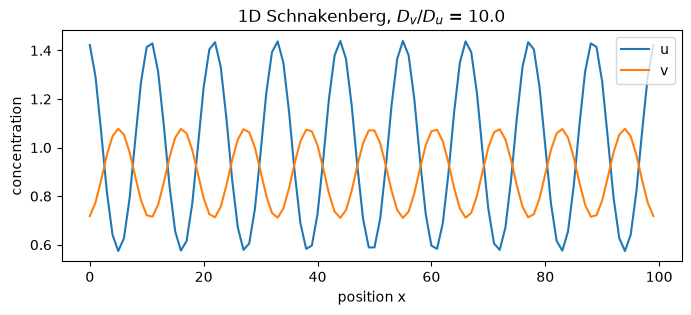

In [14]:
"""1-`D simulation"""
N1 = 100
Dv = 10.0
U1, V1 = simulate((N1,),Du, Dv, T=5000)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(U1, label="u")
ax.plot(V1, label="v")
ax.set_xlabel("position x")
ax.set_ylabel("concentration")
ax.set_title(f"1D Schnakenberg, $D_v/D_u$ = {Dv / Du:.1f}")
ax.legend()
plt.show()


In [15]:
def dominant_wavelength(V, dx=1.0):
    Vc = V - V.mean()
    mirrored = np.concatenate([Vc, Vc[::-1]])
    spectrum = np.abs(np.fft.rfft(mirrored))
    n = np.argmax(spectrum[1:]) + 1
    L = len(V) * dx
    alpha = n * np.pi / L
    return 2 * np.pi / alpha
theory = turing_analysis(a, b, Du, Dv)
print(f"Measured wavelength:  {dominant_wavelength(V1):.1f}")
print(f"Predicted (linear theory): {theory['wavelength']:.1f}")
print("Only wavenumbers alpha = n*pi/L are allowed on a finite domain, so the measured")
print("value is the allowed mode closest to the predicted one.")

Measured wavelength:  11.1
Predicted (linear theory): 10.6
Only wavenumbers alpha = n*pi/L are allowed on a finite domain, so the measured
value is the allowed mode closest to the predicted one.


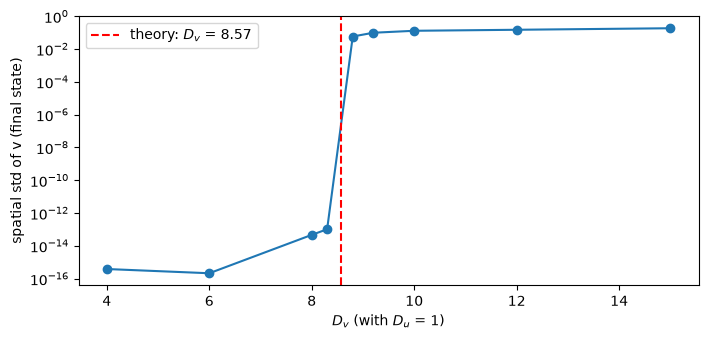

D_v =   4.0  pattern in simulation: False  theory predicts: False
D_v =   6.0  pattern in simulation: False  theory predicts: False
D_v =   8.0  pattern in simulation: False  theory predicts: False
D_v =   8.3  pattern in simulation: False  theory predicts: False
D_v =   8.8  pattern in simulation: True   theory predicts: True 
D_v =   9.2  pattern in simulation: True   theory predicts: True 
D_v =  10.0  pattern in simulation: True   theory predicts: True 
D_v =  12.0  pattern in simulation: True   theory predicts: True 
D_v =  15.0  pattern in simulation: True   theory predicts: True 


In [16]:
Dv_values = [4, 6, 8, 8.3, 8.8, 9.2, 10, 12, 15]
amplitudes = []
for Dv_i in Dv_values:
    _, V_i = simulate((N1,), Du, Dv_i, T=5000)
    amplitudes.append(V_i.std())
amplitudes = np.array(amplitudes)
pattern = amplitudes > 1e-3
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogy(Dv_values, np.maximum(amplitudes, 1e-16), "o-")
ax.axvline(crit_Dv, color="red", ls="--", label=f"theory: $D_v$ = {crit_Dv:.2f}")
ax.set_xlabel("$D_v$ (with $D_u$ = 1)")
ax.set_ylabel("spatial std of v (final state)")
ax.legend()
plt.show()
for Dv_i, amp, p in zip(Dv_values, amplitudes, pattern):
    theory_says = Dv_i > crit_Dv
    print(f"D_v = {Dv_i:5.1f}  pattern in simulation: {p!s:5}  theory predicts: {theory_says!s:5}")

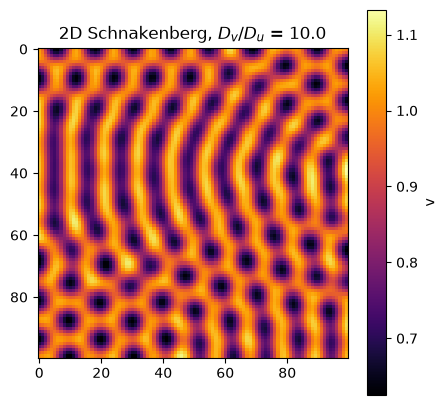

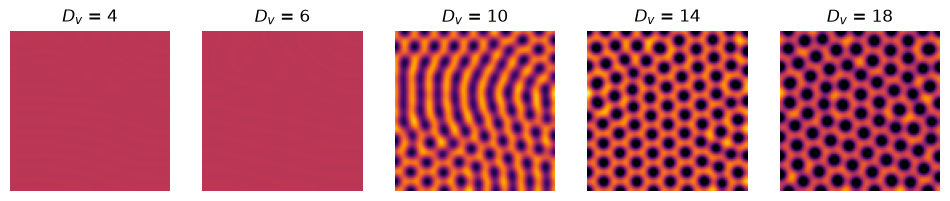

In [9]:
"""2-d simulation"""
N2 = 100
Dv = 10.00
U2, V2 = simulate((N2, N2), Du, Dv, T=2000)
fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(V2, cmap="inferno")
fig.colorbar(im, ax=ax, label="v")
ax.set_title(f"2D Schnakenberg, $D_v/D_u$ = {Dv / Du:.1f}")
plt.show()
Dvs = [4, 6, 10, 14, 18]
fig, axes = plt.subplots(1, 5, figsize=(12, 4))
for ax, Dv_i in zip(axes, Dvs):
    _, V_i = simulate((N2, N2), Du, Dv_i, T=2000)
    ax.imshow(V_i, cmap="inferno", vmin=v_st - 0.3, vmax=v_st + 0.3)
    ax.set_title(f"$D_v$ = {Dv_i}")
    ax.axis("off")
plt.show()

### Conclusion

This project asked for which parameters a steady state becomes unstable with the addition of diffusion and what pattern spacing the theory predicts. A linear stability analysis gave explicit conditions and a numerical sumilation of the Schnakenberg model was used to test them.


##### Main results

- The analysis showed that a Turing instability requires an activator–inhibitor-type kinetics ($f_u > 0$, $g_v < 0$) together with $D_v/D_u > |g_v|/f_u > 1$, plus the discriminant condition. For the parameters $a = 0.1$, $b = 0.9$ this gives a threshold $D_v/D_u \approx 8.57$.
- In 1D simulations the uniform state remained flat for $D_v \le 8.3$ and developed a pattern for $D_v \ge 8.8$, consistent with the predicted threshold.
- At $D_v = 10$ the theory predicts a wavelength of about 10.6, and the simulation produced a wavelength of about 11.1. The small difference is expected, since on a finite domain only wavenumbers $\alpha = n\pi/L$ are allowed.
- In 2D the same mechanism produced a mixture of spots and stripes.

##### Interpretation

The simulation agrees with the linear theory. The key finding is that diffusion, which normally smooths concentrations, can destabilise a uniform state when the two species diffuse at sufficiently different rates, and that the pattern spacing is set by the reaction and diffusion parameters rather than by the size of the domain. It's important to note the fact that the Schnakenberg model is very simplified. The project shows how the mechanism works mathematically and can not be applied to finding the cause of pattern on animals and plants.

##### Limitations

- **Linear theory only.** The stability analysis is valid for small perturbations of the uniform steady state. It predicts whether a pattern starts to form and its initial wavelength, but not the final shape. In the 2D simulation the result is a mixture of spots and stripes with defects where differently oriented domains meet, and the linear theory cannot say which of these shapes will win.
- **The threshold is only bracketed.** The 1D sweep tested a finite set of values of $D_v$, so the threshold is confirmed to lie between 8.3 and 8.8, while the theory gives 8.57. Near the threshold the growth rate of the unstable modes is very small, so a run of finite duration ($T = 5000$) could look flat even though the state is slightly unstable. The criterion used to decide that a pattern had formed (spatial standard deviation above $10^{-3}$) is also a choice, though the values separate clearly: about $10^{-13}$ without a pattern and about $10^{-1}$ with one.
- **The wavelength was compared at a single $D_v$.** On a finite domain only the wavenumbers $\alpha = n\pi/L$ are allowed, so the simulation can only select the allowed mode closest to the predicted one. This is why 11.1 and 10.6 cannot coincide exactly, and a single comparison cannot show how well the theory tracks the wavelength as parameters change.
- **A narrow set of conditions.** All results are for one model (Schnakenberg), one parameter set ($a = 0.1$, $b = 0.9$, $D_u = 1$), one random initial condition (fixed seed), one domain size ($L = 100$), and no-flux boundaries. Other choices could change the details, such as the exact wavelength and the number of defects.
- **Numerical method.** The simulation uses explicit Euler, which is only first-order accurate, on a grid with $dx = 1$. The time step satisfies the stability limit, but no refinement study (smaller $dt$ and $dx$) was carried out to show that the results do not depend on the discretisation.
- **2D results are qualitative.** The 2D simulations show that patterns form where the theory predicts, but no quantitative comparison (for example of the 2D wavelength) was made.
- **Model scope.** The Schnakenberg model is a simplified, dimensionless example, so the wavelength here is not a physical length. The project shows that the mechanism works mathematically and does not establish what causes any specific pattern in a real organism.


##### Further work
- **Wavelength as a function of $D_v$.** Repeat the wavelength measurement over a range of $D_v$ values and plot the measured wavelength against the theoretical $2\pi/\alpha_{\max}$, which would be a much stronger test of the theory than a single point.
- **Validation of the numerics.** Halve $dt$ and $dx$ and check that the threshold and wavelength are unchanged, and repeat the runs with several random seeds.
- **Domain-size test.** Run with $L = 200$ and check that the number of stripes roughly doubles while the spacing stays the same, which would support the claim that the pattern spacing is set by the kinetics and diffusion rather than by the domain.
- **The full Turing region.** Apply the derived conditions over a grid of $(a, b)$ or $(a, D_v)$ values to map the region of instability, and check a few points on its boundary by simulation.
- **Boundary conditions.** Compare no-flux with periodic boundaries, which have different sets of allowed modes.
- **Quantitative 2D analysis.** Measure the 2D wavelength from the radially averaged Fourier spectrum, and quantify how the pattern depends on $D_v$.
- **Beyond linear theory.** Use a weakly nonlinear (amplitude equation) analysis to predict whether spots or stripes appear, which linear theory cannot do.
- **Other models and methods.** Repeat the study for the Gray–Scott model, whose richer patterns have a less transparent analysis, and use more accurate time-stepping (for example, semi-implicit or spectral methods), which would also allow larger time steps.

## Literature

- [Turing, A. M. (1952). The chemical basis of morphogenesis. Philosophical Transactions of the Royal Society of London. Series B, Biological Sciences, 237(641), 37–72.](https://www.dna.caltech.edu/courses/cs191/paperscs191/turing.pdf)
- [Beentjes, C. H. L. (2014). Pattern formation analysis in the Schnakenberg model (Mathematical Institute Technical  Report). University of Oxford](https://cbeentjes.github.io/files/Ramblings/PatternFormationSchnakenberg.pdf)
- [Sims, K. (2013–2016). Reaction-diffusion tutorial.](https://www.karlsims.com/rd.html)
- [Ben Tahar Soha, 2022, Modelling of pattern formation and growth driven by reaction-diffusion equations (Master's thesis). Universitat Politècnica de Catalunya Barcelona École des Ponts ParisTech](https://upcommons.upc.edu/server/api/core/bitstreams/93cd86e5-f682-42a4-aba6-fa3e2823fb96/content)
- [Steve Brunton (2022), Linearization (YouTube lecture)](https://www.youtube.com/watch?v=RCWkzzLgwf0&t=739s)